# SM Lab / Спортмастер: воронка онлайн-продаж

Задача исследования - изучить события просмотров товаров, определить особенности данных, влияющие на настройку AutoML для прогноза добавления товара в корзину (`add_to_cart_flag`) или оформления заказа (`create_order_flag`). Рассматриваются две бинарные классификации с разными моментами прогнозирования.

Источник: [DANO 2024, SM Lab / Спортмастер](https://dano.hse.ru/data2024). Результаты и выводы представлены в `EDA_sm_lab_sales_funnel.md`.

Архив [SM Lab DATASET-20261119T095343Z-1-001.zip](https://drive.google.com/file/d/1at46czvoi1PzNFU_2dKsYnVclfZrWJpC/view?usp=drive_link) содержит четыре CSV: `sportmaster_full_dataset..csv`, `sm_small_random.csv`, `sm_small_onlyMostFrequent.csv`, `sm_verySmall_random.csv`. Архив размещается рядом с ноутбуком. Ячейки выполняются последовательно сверху вниз. Используются `pandas`, `numpy`, `matplotlib`.

## 1. Первичный анализ

Проверяются состав четырёх версий, размерность и ключевые признаки. Полный файл читается частями, чтобы не загружать 7 млн событий целиком.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

archive_path = Path("SM Lab DATASET-20261119T095343Z-1-001.zip")
assert archive_path.is_file(), f"Не найден архив: {archive_path.name}"
file_names = {
    "full": "sportmaster_full_dataset..csv",
    "small_random": "sm_small_random.csv",
    "small_frequent": "sm_small_onlyMostFrequent.csv",
    "very_small": "sm_verySmall_random.csv",
}
with ZipFile(archive_path) as zf:
    members = {Path(n).name: n for n in zf.namelist() if n.endswith(".csv")}
    missing = sorted(set(file_names.values()) - set(members))
    assert not missing, f"В архиве отсутствуют: {missing}"
    schemes = {key: pd.read_csv(zf.open(members[name]), nrows=0).columns.tolist()
               for key, name in file_names.items()}

schema_table = pd.DataFrame({"Таблица": list(file_names.values()),
                             "Столбцов": [len(schemes[k]) for k in file_names],
                             "Есть ret_discount": ["ret_discount" in schemes[k] for k in file_names]})
display(schema_table)
print("Поля полного CSV:", schemes["full"])

,Таблица,Столбцов,Есть ret_discount
0,sportmaster_full_dataset..csv,19,True
1,sm_small_random.csv,18,False
2,sm_small_onlyMostFrequent.csv,18,False
3,sm_verySmall_random.csv,18,False


Поля полного CSV: ['device_type', 'event_id', 'user_id', 'user_is_authorized', 'location_id', 'create_timestamp', 'product_id', 'product_is_pick_up', 'product_is_pick_point', 'product_is_delivery', 'product_is_now', 'product_price', 'ret_discount', 'product_category', 'product_gender', 'product_age', 'brand_lvl', 'add_to_cart_flag', 'create_order_flag']


## 2. Целевая переменная и этапы воронки

`add_to_cart_flag` означает добавление товара в корзину после просмотра; `create_order_flag` отражает последующее оформление заказа. При прогнозировании заказа в момент просмотра добавление в корзину не является допустимым признаком.

In [2]:
# Подготавливаются небольшие выборки идентификаторов для сравнения версий.
SAMPLE_SIZE = 40_000
with ZipFile(archive_path) as zf:
    samples = {
        key: pd.read_csv(zf.open(members[file_names[key]]), nrows=SAMPLE_SIZE,
                         dtype={"event_id": "string", "brand_lvl": "string"})
        for key in ("small_random", "small_frequent", "very_small")
    }
wanted_ids = set().union(*(set(x.event_id.dropna()) for x in samples.values()))
print("Сопоставляемых event_id (объединение трёх выборок):", len(wanted_ids))

Сопоставляемых event_id (объединение трёх выборок): 118439


In [3]:
# Счётчики и множества инициализируются один раз перед потоковым анализом.
CHUNK_SIZE = 100_000
count_rows = 0
missing_count = Counter()
cat_count = {c: Counter() for c in ["device_type", "product_category", "product_gender", "product_age", "brand_lvl", "user_is_authorized"]}
by_group = {c: defaultdict(lambda: [0, 0, 0]) for c in ["device_type", "product_category", "product_gender", "brand_lvl", "user_is_authorized", "product_is_delivery", "product_is_pick_up"]}
by_day = defaultdict(lambda: [0, 0, 0])
by_hour = defaultdict(lambda: [0, 0, 0])
user_counts, product_counts = Counter(), Counter()
event_ids = set()
early_users, late_users, early_products, late_products = set(), set(), set(), set()
target_cart = target_order = target_order_without_cart = 0
price_n = price_sum = discount_sum = 0
price_min, price_max, discount_max = np.inf, -np.inf, -np.inf
zero_price = negative_price = discount_over_price = negative_after_discount = 0
invalid_flags = Counter()
invalid_dates = 0
first_ts, last_ts = pd.Timestamp.max, pd.Timestamp.min
price_sample = []
matched_full = {}

# Граница применяется только для диагностического временного разбиения.
split_date = pd.Timestamp("2024-06-15")

def add_group(source, key, cart, order):
    for group, row in pd.DataFrame({"key": key, "cart": cart, "order": order}).groupby("key", dropna=False).agg(
            n=("cart", "size"), cart=("cart", "sum"), order=("order", "sum")).iterrows():
        arr = source[str(group)]
        arr[0] += int(row["n"])
        arr[1] += int(row["cart"])
        arr[2] += int(row["order"])

In [4]:
# Полный проход по 7 млн строк; точные количества считаются по всем событиям.
with ZipFile(archive_path) as zf:
    reader = pd.read_csv(zf.open(members[file_names["full"]]), chunksize=CHUNK_SIZE,
                         dtype={"event_id": "string"}, low_memory=False)
    for part, chunk in enumerate(reader):
        count_rows += len(chunk)
        missing_count.update(chunk.isna().sum().astype(int).to_dict())
        for col in cat_count:
            cat_count[col].update(chunk[col].value_counts(dropna=False).to_dict())
        for col in by_group:
            values = (pd.to_numeric(chunk[col], errors="coerce").astype("Int64")
                      if col.startswith("product_is_") else chunk[col])
            add_group(by_group[col], values, chunk.add_to_cart_flag, chunk.create_order_flag)
        target_cart += int(chunk.add_to_cart_flag.sum())
        target_order += int(chunk.create_order_flag.sum())
        target_order_without_cart += int(((chunk.create_order_flag == 1) &
                                          (chunk.add_to_cart_flag != 1)).sum())
        for col in ["add_to_cart_flag", "create_order_flag", "user_is_authorized",
                    "product_is_pick_up", "product_is_pick_point",
                    "product_is_delivery", "product_is_now"]:
            invalid_flags[col] += int((~chunk[col].isin([0, 1]) & chunk[col].notna()).sum())
        event_ids.update(chunk.event_id.dropna())
        user_counts.update(chunk.user_id.value_counts(dropna=True).to_dict())
        product_counts.update(chunk.product_id.value_counts(dropna=True).to_dict())
        price = pd.to_numeric(chunk.product_price, errors="coerce")
        disc = pd.to_numeric(chunk.ret_discount, errors="coerce")
        price_n += int(price.notna().sum())
        price_sum += float(price.sum())
        discount_sum += float(disc.sum())
        price_min = min(price_min, float(price.min()))
        price_max = max(price_max, float(price.max()))
        discount_max = max(discount_max, float(disc.max()))
        zero_price += int((price == 0).sum())
        negative_price += int((price < 0).sum())
        discount_over_price += int((disc > price).sum())
        negative_after_discount += int(((price - disc) < 0).sum())
        price_sample.append(price.dropna().sample(min(400, price.notna().sum()), random_state=2024 + part))
        ts = pd.to_datetime(chunk.create_timestamp, errors="coerce")
        invalid_dates += int(ts.isna().sum() - chunk.create_timestamp.isna().sum())
        first_ts, last_ts = min(first_ts, ts.min()), max(last_ts, ts.max())
        add_group(by_day, ts.dt.strftime("%Y-%m-%d"), chunk.add_to_cart_flag, chunk.create_order_flag)
        add_group(by_hour, ts.dt.hour, chunk.add_to_cart_flag, chunk.create_order_flag)
        is_early = ts < split_date
        early_users.update(chunk.loc[is_early, "user_id"].dropna().unique())
        late_users.update(chunk.loc[~is_early, "user_id"].dropna().unique())
        early_products.update(chunk.loc[is_early, "product_id"].dropna().unique())
        late_products.update(chunk.loc[~is_early, "product_id"].dropna().unique())
        interesting = chunk[chunk.event_id.isin(wanted_ids)]
        for rec in interesting[["event_id", "user_id", "product_price", "ret_discount", "brand_lvl",
                                "add_to_cart_flag", "create_order_flag"]].itertuples(index=False, name=None):
            matched_full[rec[0]] = rec[1:]

price_sample = pd.concat(price_sample, ignore_index=True)
print("Строк:", count_rows, "; уникальных event_id:", len(event_ids),
      "; повторных event_id:", count_rows - len(event_ids))
print("Диапазон времени:", first_ts, "—", last_ts)
print("Цели: корзина", target_cart, "; заказ", target_order,
      "; заказ без корзины", target_order_without_cart)

Строк: 7000000 ; уникальных event_id: 6999966 ; повторных event_id: 34
Диапазон времени: 2024-06-01 00:00:00.325000 — 2024-06-21 09:20:02.259000
Цели: корзина 1315513 ; заказ 350303 ; заказ без корзины 0


In [5]:
print("Число уникальных user_id:", len(user_counts))
print("Число уникальных product_id:", len(product_counts))
display(pd.DataFrame({"Признак": list(missing_count), "Пропусков": list(missing_count.values()),
                      "Доля, %": [round(v / count_rows * 100, 5) for v in missing_count.values()]}).sort_values("Пропусков", ascending=False).head(12))

Число уникальных user_id: 2108035
Число уникальных product_id: 90613


,Признак,Пропусков,"Доля, %"
8,product_is_pick_point,11,0.00016
9,product_is_delivery,11,0.00016
10,product_is_now,11,0.00016
7,product_is_pick_up,11,0.00016
2,user_id,0,0.00000
0,device_type,0,0.00000
1,event_id,0,0.00000
6,product_id,0,0.00000
5,create_timestamp,0,0.00000
4,location_id,0,0.00000


,Этап,Событий,"Доля просмотров, %"
0,Просмотр карточки,7000000,100.000
1,Добавление в корзину,1315513,18.793
2,Оформление заказа,350303,5.004


Заказ после добавления в корзину, %: 26.63


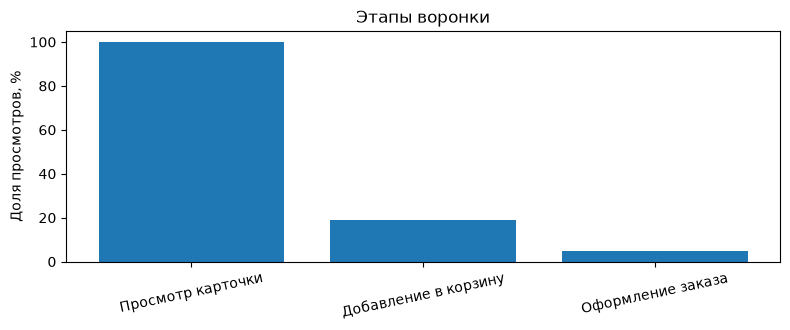

In [6]:
funnel = pd.DataFrame({"Этап": ["Просмотр карточки", "Добавление в корзину", "Оформление заказа"],
                       "Событий": [count_rows, target_cart, target_order],
                       "Доля просмотров, %": [100, 100*target_cart/count_rows, 100*target_order/count_rows]})
display(funnel.round(3))
print("Заказ после добавления в корзину, %:", round(100*target_order/target_cart, 2))
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(funnel["Этап"], funnel["Доля просмотров, %"])
ax.set_ylabel("Доля просмотров, %")
ax.set_title("Этапы воронки")
plt.xticks(rotation=12)
plt.tight_layout(); plt.show()

## 3. Пропуски, дубликаты и специальные значения

Проверяются идентификаторы событий, пропуски, бинарные поля, цены и коды уровня бренда. Отсутствие обычных `NaN` не означает отсутствие смысловых аномалий.

In [7]:
print("Повторных event_id:", count_rows - len(event_ids))
print("Некорректных непустых create_timestamp:", invalid_dates)
print("Небинарных значений:")
display(pd.Series(invalid_flags, name="Строк").to_frame())
print("Строк с ret_discount > product_price:", discount_over_price)
print("Строк с отрицательной ценой после скидки:", negative_after_discount)
print("Значения brand_lvl в полном файле:")
display(pd.Series(cat_count["brand_lvl"], name="Количество").sort_index().to_frame())

Повторных event_id: 34
Некорректных непустых create_timestamp: 0
Небинарных значений:


,Строк
add_to_cart_flag,0
create_order_flag,0
user_is_authorized,0
product_is_pick_up,0
product_is_pick_point,0
product_is_delivery,0
product_is_now,0


Строк с ret_discount > product_price: 0
Строк с отрицательной ценой после скидки: 0
Значения brand_lvl в полном файле:


,Количество
0,1802151
1,2233791
2,2964058


## 4. Цены, товары и категориальные признаки

Цена полного файла указывается до скидки, а `ret_discount` хранится отдельно. Для квантилей цен применяется воспроизводимая выборка из всех частей CSV; минимум, максимум и среднее рассчитаны по всем строкам.

Цена, минимум / максимум: 25.0 / 991600.0
Цена, среднее (точно): 6081.76
Цена, медиана / P90 / P99 (приближённо): {0.5: 3799.0, 0.9: 11999.0, 0.99: 39002.0}
Максимальная скидка: 97950.0
Нулевая цена: 0 ; отрицательная цена: 0
Строк с отрицательной ценой после скидки: 0


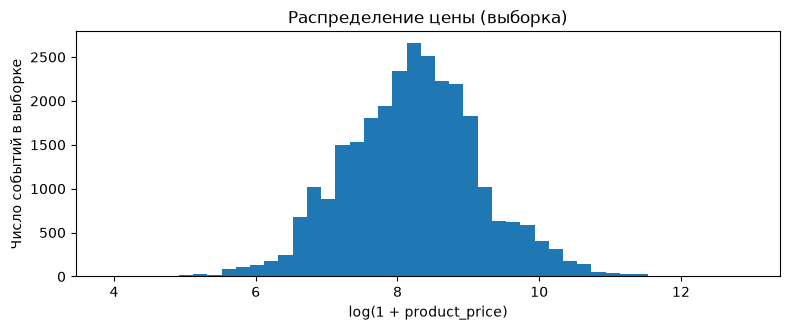

In [8]:
print("Цена, минимум / максимум:", price_min, "/", price_max)
print("Цена, среднее (точно):", round(price_sum / price_n, 2))
print("Цена, медиана / P90 / P99 (приближённо):",
      price_sample.quantile([0.5, 0.9, 0.99]).round(2).to_dict())
print("Максимальная скидка:", discount_max)
print("Нулевая цена:", zero_price, "; отрицательная цена:", negative_price)
print("Строк с отрицательной ценой после скидки:", negative_after_discount)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(np.log1p(price_sample.clip(lower=0)), bins=45)
ax.set_xlabel("log(1 + product_price)")
ax.set_ylabel("Число событий в выборке")
ax.set_title("Распределение цены (выборка)")
plt.tight_layout(); plt.show()

In [9]:
for col in ["product_category", "product_gender", "product_age", "device_type"]:
    display(pd.Series(cat_count[col], name="Событий").sort_values(ascending=False).head(12).to_frame()
            .rename_axis(col))

,Событий
product_category,
одежда,3353274
обувь,2705633
инвентарь,941093


,Событий
product_gender,
мужской,3324291
женский,2326424
унисекс,1349285


,Событий
product_age,
взрослые,6187736
дети,794105
малыши,18159


,Событий
device_type,
mobileapp_android,4010713
mobileapp_ios,2176037
desktop,813250


In [10]:
def group_frame(source, label, min_n=1):
    frame = pd.DataFrame.from_dict(source, orient="index", columns=["Событий", "Корзин", "Заказов"])
    frame.index.name = label
    frame = frame[frame["Событий"] >= min_n].copy()
    frame["В корзину, %"] = (frame["Корзин"] / frame["Событий"] * 100).round(2)
    frame["Заказов, %"] = (frame["Заказов"] / frame["Событий"] * 100).round(2)
    return frame.sort_values("Событий", ascending=False)

for col in ["device_type", "user_is_authorized", "product_is_delivery", "product_category"]:
    print("Признак:", col)
    display(group_frame(by_group[col], col).head(10))

Признак: device_type


,Событий,Корзин,Заказов,"В корзину, %","Заказов, %"
device_type,,,,,
mobileapp_android,4010713,773334,208377,19.28,5.20
mobileapp_ios,2176037,442003,119599,20.31,5.50
desktop,813250,100176,22327,12.32,2.75


Признак: user_is_authorized


,Событий,Корзин,Заказов,"В корзину, %","Заказов, %"
user_is_authorized,,,,,
1,6084317,1247109,347141,20.50,5.71
0,915683,68404,3162,7.47,0.35


Признак: product_is_delivery


,Событий,Корзин,Заказов,"В корзину, %","Заказов, %"
product_is_delivery,,,,,
1,6491159,1265408,343319,19.49,5.29
0,508830,50102,6984,9.85,1.37
<NA>,11,3,0,27.27,0.00


Признак: product_category


,Событий,Корзин,Заказов,"В корзину, %","Заказов, %"
product_category,,,,,
одежда,3353274,667765,178302,19.91,5.32
обувь,2705633,469492,122136,17.35,4.51
инвентарь,941093,178256,49865,18.94,5.30


## 5. Повторные пользователи, товары и зависимость наблюдений

Один пользователь и один товар могут участвовать в нескольких событиях. Это важно при выборе способа разбиения и оценке качества на новых объектах.

Уникальных пользователей: 2108035 ; товаров: 90613
Пользователей с несколькими событиями: 1097741 ; доля, %: 52.07
Максимум событий пользователя: 2401 ; P50/P90/P99: {0.5: 2.0, 0.9: 7.0, 0.99: 25.0}
Максимум событий товара: 19697 ; P50/P90/P99: {0.5: 5.0, 0.9: 152.0, 0.99: 1256.640000000014}


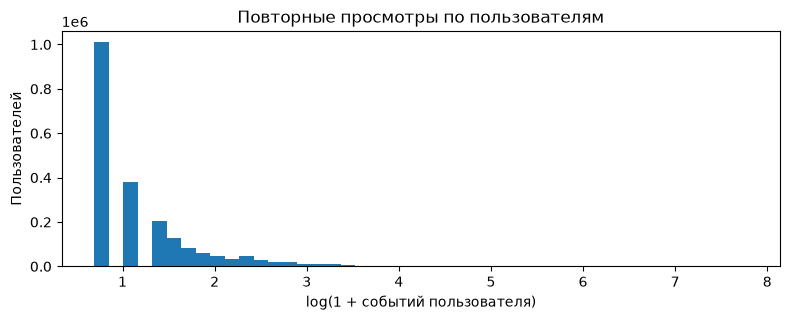

In [11]:
u = pd.Series(user_counts, dtype="int64")
p = pd.Series(product_counts, dtype="int64")
print("Уникальных пользователей:", len(u), "; товаров:", len(p))
print("Пользователей с несколькими событиями:", int((u>1).sum()),
      "; доля, %:", round(100*(u>1).mean(), 2))
print("Максимум событий пользователя:", int(u.max()),
      "; P50/P90/P99:", u.quantile([.5,.9,.99]).to_dict())
print("Максимум событий товара:", int(p.max()),
      "; P50/P90/P99:", p.quantile([.5,.9,.99]).to_dict())
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.hist(np.log1p(u.to_numpy()), bins=45)
ax.set_xlabel("log(1 + событий пользователя)")
ax.set_ylabel("Пользователей")
ax.set_title("Повторные просмотры по пользователям")
plt.tight_layout(); plt.show()

## 6. Временная структура

Анализируются ежедневные доли добавлений в корзину и заказов, неполнота последнего дня и пересечения пользователей и товаров между периодами.

,Событий,Корзин,Заказов,"В корзину, %","Заказов, %"
Дата,,,,,
2024-06-01,392348,74452,20010,18.98,5.10
2024-06-02,460033,92802,28298,20.17,6.15
2024-06-03,419451,84498,25535,20.14,6.09
2024-06-04,380268,69159,16829,18.19,4.43
2024-06-05,343350,63180,15826,18.40,4.61
2024-06-06,341320,63580,16243,18.63,4.76
2024-06-07,316167,58830,14910,18.61,4.72
2024-06-08,355752,68074,18443,19.14,5.18
2024-06-09,413801,80542,22975,19.46,5.55


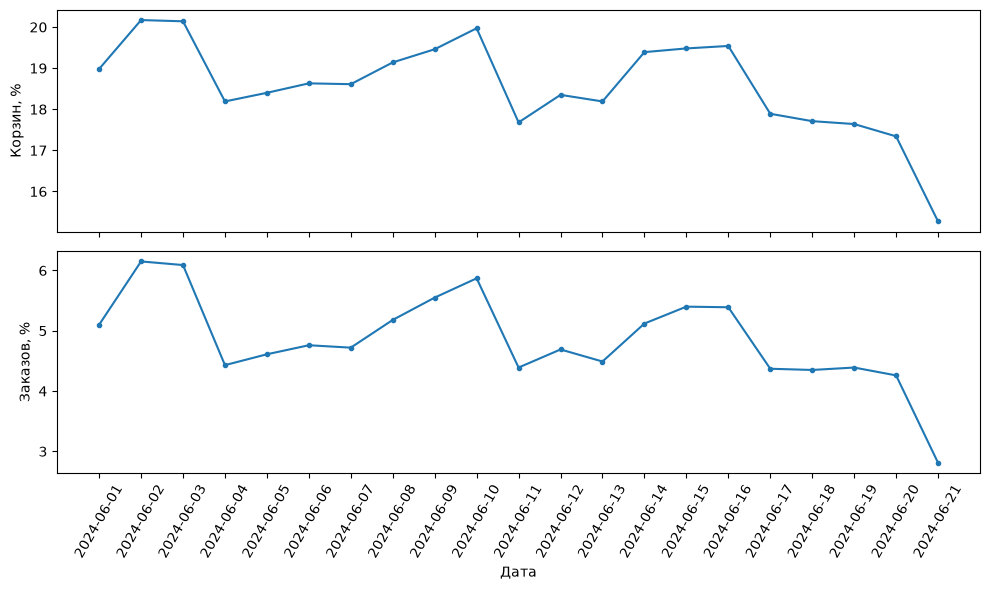

In [12]:
daily = group_frame(by_day, "Дата").sort_index()
display(daily)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(daily.index, daily["В корзину, %"], marker="o", markersize=3)
axes[0].set_ylabel("Корзин, %")
axes[1].plot(daily.index, daily["Заказов, %"], marker="o", markersize=3)
axes[1].set_ylabel("Заказов, %")
axes[1].set_xlabel("Дата")
plt.xticks(rotation=60)
plt.tight_layout();plt.show()

,Событий,Корзин,Заказов,"В корзину, %","Заказов, %"
Час,,,,,
0,181835,27075,5963,14.89,3.28
1,108061,15838,3525,14.66,3.26
10,381362,73509,20340,19.28,5.33
11,403635,78446,21827,19.43,5.41
12,418615,82896,23609,19.80,5.64
13,400832,80195,22861,20.01,5.70
14,392892,78651,22849,20.02,5.82
15,383659,77244,22396,20.13,5.84
16,384528,76821,21890,19.98,5.69


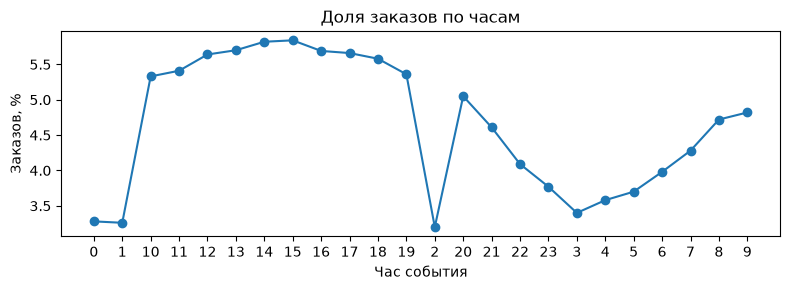

In [13]:
hourly = group_frame(by_hour, "Час").sort_index()
display(hourly)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(hourly.index, hourly["Заказов, %"], marker="o")
ax.set_xlabel("Час события")
ax.set_ylabel("Заказов, %")
ax.set_title("Доля заказов по часам")
plt.tight_layout();plt.show()

In [14]:
print("Ранняя часть: 01-14 июня; поздняя: 15-21 июня")
print("Пользователи ранней / поздней частей:", len(early_users), len(late_users))
print("Общие пользователи:", len(early_users & late_users))
print("Товары ранней / поздней частей:", len(early_products), len(late_products))
print("Общие товары:", len(early_products & late_products))
print("Количество событий последнего и предыдущего дней:",
      daily.loc["2024-06-21", "Событий"], daily.loc["2024-06-20", "Событий"])

Ранняя часть: 01-14 июня; поздняя: 15-21 июня
Пользователи ранней / поздней частей: 1643591 771557
Общие пользователи: 307113
Товары ранней / поздней частей: 81589 63712
Общие товары: 54688
Количество событий последнего и предыдущего дней: 62215 296342


## 7. Сопоставление полной и сокращённых версий

Малые CSV не являются независимыми тестовыми наборами: это преобразованные подвыборки полного файла. Проверяется пересечение `event_id`, структура, соотношение исходов, изменение цены и кодирования `brand_lvl`.

In [15]:
small_stats = {}
with ZipFile(archive_path) as zf:
    for key in ("small_random", "small_frequent", "very_small"):
        seen_ids, users = set(), set()
        n = cart = order = overlap = 0
        nmissing = Counter()
        brand = Counter()
        device = Counter()
        for ch in pd.read_csv(zf.open(members[file_names[key]]), chunksize=CHUNK_SIZE,
                              dtype={"event_id": "string", "brand_lvl": "string"}, low_memory=False):
            n += len(ch)
            cart += int(ch.add_to_cart_flag.sum())
            order += int(ch.create_order_flag.sum())
            overlap += sum(eid in event_ids for eid in ch.event_id.dropna())
            seen_ids.update(ch.event_id.dropna())
            users.update(ch.user_id.dropna().unique())
            nmissing.update(ch.isna().sum().astype(int).to_dict())
            brand.update(ch.brand_lvl.value_counts(dropna=False).to_dict())
            device.update(ch.device_type.value_counts(dropna=False).to_dict())
        small_stats[key] = {"rows": n, "cart": cart, "order": order,
                            "unique_user":len(users), "unique_event":len(seen_ids),
                            "matched_full":overlap,"dup_extra":n-len(seen_ids),
                            "missing":dict(nmissing), "brand":dict(brand), "device":dict(device)}

all_stats = {"full": {"rows":count_rows, "cart":target_cart, "order":target_order,
                      "unique_user":len(user_counts), "unique_event":len(event_ids),
                      "matched_full":count_rows, "dup_extra":count_rows-len(event_ids)}, **small_stats}
comparison = pd.DataFrame.from_dict({key: {"Строк":s["rows"], "Уникальных событий":s["unique_event"],
        "Уникальных пользователей":s["unique_user"], "Есть в full":s["matched_full"],
        "В корзину, %":round(100*s["cart"]/s["rows"],2),
        "Заказов, %":round(100*s["order"]/s["rows"],2)} for key,s in all_stats.items()}, orient="index")
display(comparison)

,Строк,Уникальных событий,Уникальных пользователей,Есть в full,"В корзину, %","Заказов, %"
full,7000000,6999966,2108035,7000000,18.79,5.00
small_random,996899,996895,300000,996899,18.85,5.09
small_frequent,499991,499988,9337,499991,19.06,5.59
very_small,99617,99617,30000,99617,18.86,5.09


In [16]:
for key in small_stats:
    print(key, "- brand_lvl:")
    display(pd.Series(small_stats[key]["brand"], name="Событий").sort_values(ascending=False).to_frame())
    print("Пропуски:", {k:v for k,v in small_stats[key]["missing"].items() if v})

small_random - brand_lvl:


,Событий
2,394114
1,317600
0,257539
noinfo,26554
-3,875
-1,217


Пропуски: {'product_is_pick_up': 2, 'product_is_pick_point': 2, 'product_is_delivery': 2, 'product_is_now': 2}
small_frequent - brand_lvl:


,Событий
2,182914
1,180790
0,123591
noinfo,12187
-3,444
-1,65


Пропуски: {}
very_small - brand_lvl:


,Событий
2,39557
1,31831
0,25497
noinfo,2646
-3,69
-1,17


Пропуски: {}


In [17]:
# На одинаковых event_id сравниваются исходные и преобразованные поля.
match_rows = []
for key, sample in samples.items():
    valid = sample[sample.event_id.isin(matched_full)].copy()
    full_data = [matched_full[x] for x in valid.event_id]
    full_price = pd.Series([r[1] for r in full_data], index=valid.index, dtype="float64")
    full_discount = pd.Series([r[2] for r in full_data], index=valid.index, dtype="float64")
    full_user = pd.Series([r[0] for r in full_data], index=valid.index)
    full_brand = pd.Series([str(r[3]) for r in full_data], index=valid.index)
    valid_price = pd.to_numeric(valid.product_price, errors="coerce")
    match_rows.append({"Версия":key, "Выборка":len(sample),"Сопоставлено":len(valid),
        "Цена_малой_равна_цене_за_вычетом_скидки":int(((valid_price - (full_price-full_discount)).abs()<0.0001).sum()),
        "Отличается_user_id":int((valid.user_id != full_user).sum()),
        "Отличается_brand_lvl":int((valid.brand_lvl.astype("string") != full_brand.astype("string")).sum())})
display(pd.DataFrame(match_rows))

,Версия,Выборка,Сопоставлено,Цена_малой_равна_цене_за_вычетом_скидки,Отличается_user_id,Отличается_brand_lvl
0,small_random,40000,40000,40000,13523,1665
1,small_frequent,40000,40000,40000,37398,912
2,very_small,40000,40000,40000,37400,1076


## 8. Различия между версиями и риски смешивания данных

Изменения цены, кодирования бренда и идентификаторов пользователей означают, что небольшие версии нельзя без проверки объединять с полной таблицей или использовать для оценки на независимом test. Наблюдаемые изменения проверяются на совпадающих событиях.

In [18]:
print("Полная таблица, топ устройств:")
display(group_frame(by_group["device_type"], "device_type"))
for key in small_stats:
    s=small_stats[key]
    print(key, ": доля совпавших с full event_id, %:", round(100*s["matched_full"]/s["rows"],2),
          "; среднее число событий на пользователя:", round(s["rows"]/s["unique_user"],2))

Полная таблица, топ устройств:


,Событий,Корзин,Заказов,"В корзину, %","Заказов, %"
device_type,,,,,
mobileapp_android,4010713,773334,208377,19.28,5.20
mobileapp_ios,2176037,442003,119599,20.31,5.50
desktop,813250,100176,22327,12.32,2.75


small_random : доля совпавших с full event_id, %: 100.0 ; среднее число событий на пользователя: 3.32
small_frequent : доля совпавших с full event_id, %: 100.0 ; среднее число событий на пользователя: 53.55
very_small : доля совпавших с full event_id, %: 100.0 ; среднее число событий на пользователя: 3.32


## 9. Ограничения валидации и признаки для AutoML

Для прогноза на этапе просмотра доступны сведения о текущем событии и товаре. `event_id` служит идентификатором записи, а не содержательным признаком. Метки последующих действий должны быть исключены из входных признаков соответствующей задачи. Временная валидация требует учёта последнего неполного дня и неизвестного горизонта регистрации исходов.

In [19]:
available_at_view = ["device_type", "user_is_authorized", "location_id", "create_timestamp",
                     "product_id", "product_is_pick_up", "product_is_pick_point", "product_is_delivery",
                     "product_is_now", "product_price", "ret_discount", "product_category",
                     "product_gender", "product_age", "brand_lvl"]
print("Потенциальные признаки в момент просмотра:", len(available_at_view))
print("Недопустимы для прогноза заказа по просмотру: add_to_cart_flag, create_order_flag")
print("Недопустим для прогноза корзины: create_order_flag")
print("Полное число событий в каждом разбиении:")
print("Ранняя часть:", int(daily.loc[:"2024-06-14", "Событий"].sum()),
      "Поздняя часть:", int(daily.loc["2024-06-15":, "Событий"].sum()))
print("Доли заказов, %:",
      round(100 * daily.loc[:"2024-06-14", "Заказов"].sum() / daily.loc[:"2024-06-14", "Событий"].sum(), 2),
      round(100 * daily.loc["2024-06-15":, "Заказов"].sum() / daily.loc["2024-06-15":, "Событий"].sum(), 2))

Потенциальные признаки в момент просмотра: 15
Недопустимы для прогноза заказа по просмотру: add_to_cart_flag, create_order_flag
Недопустим для прогноза корзины: create_order_flag
Полное число событий в каждом разбиении:
Ранняя часть: 5119353 Поздняя часть: 1880647
Доли заказов, %: 5.14 4.65


## 10. Выводы для настройки AutoML

1. Полный файл содержит события просмотров и два бинарных исхода; конкретный целевой столбец зависит от момента прогноза (корзина или заказ).
2. При прогнозировании заказа в момент просмотра нельзя включать `add_to_cart_flag`, а при прогнозировании корзины нельзя включать последующие исходы.
3. Доля оформленных заказов существенно меньше доли добавлений в корзину; метрика должна отражать цель и цену ошибок, а не ограничиваться accuracy.
4. При прогнозе на последующие даты необходим хронологический holdout с учётом неполного последнего дня и неизвестной задержки формирования меток.
5. Повторные пользователи и товары требуют проверки качества в зависимости от бизнес-популяции; групповая и временная валидация решают разные задачи.
6. Полный и сокращённые CSV отличаются семантикой цен, значениями `brand_lvl` и для части записей идентификаторами пользователя. Смешивать варианты без согласования схемы нельзя.
7. Для основного эксперимента целесообразно использовать `sportmaster_full_dataset..csv`, а не объединять четыре перекрывающиеся версии. Входные признаки отбираются только из данных, доступных в момент требуемого прогноза.